## Scraping the web to build our dataset of 300 items ( laptop specs from x-kom )

In [ ]:
import time
import pandas as pd
from selenium import webdriver
from selenium.webdriver.common.by import By
from selenium.webdriver.chrome.service import Service
from webdriver_manager.chrome import ChromeDriverManager
from selenium.common.exceptions import NoSuchElementException

options = webdriver.ChromeOptions()
driver = webdriver.Chrome(service=Service(ChromeDriverManager().install()), options=options)

laptop_data = []

try:
    # ? page = 2, 3, 4... will be concatenated at the end of this url in the loop
    target_url = "https://www.x-kom.pl/g-2/c/159-laptopy-notebooki-ultrabooki.html"
    driver.get(target_url)

    time.sleep(3)
    
    # scroll to render
    for _ in range(5):
        driver.execute_script("window.scrollBy(0, 1000);")
        time.sleep(2)

    product_cards = driver.find_elements(By.XPATH, "//div[contains(@data-name, 'productCard')]")
    
    print(f"Found {len(product_cards)} laptops on this page. Extracting...")

    for card in product_cards:
        try:
            title = card.find_element(By.XPATH, ".//h3").text
            price = card.find_element(By.XPATH, ".//span[contains(text(), 'zł')]").text
            specs_elements = card.find_elements(By.XPATH, ".//ul//li")
            valid_specs = []
            
            for spec in specs_elements:
                text = spec.text.strip()

                if text and "zł" not in text and "Najniższa" not in text and "Cena" not in text:
                    valid_specs.append(text)
            
            specs = " | ".join(valid_specs)
            
            if not specs:
                specs = "MISSING_SPECS"

            if title:
                laptop_data.append({
                    "Title": title,
                    "Price": price,
                    "Specifications": specs,
                    "Combined_Text": f"{title} {specs}" 
                })
                
        except NoSuchElementException:
            continue

finally:
    driver.quit()

df = pd.DataFrame(laptop_data)
df.to_csv("xkom_laptops.csv", index=False)
print("Data successfully saved to xkom_laptops.csv!")
print(df.head())

## Task 1: (warm-up): Classifier Performance vs. Latent Dimensions

Objective: Evaluate how the performance of a relation classifier scales with the number of
dimensions used in a latent representation

Targeting these brands for classification: ['HP', 'Apple', 'Lenovo', 'Dell', 'ASUS']

Vectorizing laptop descriptions...


Loading weights: 100%|██████████| 103/103 [00:00<00:00, 7118.95it/s]


Evaluating Random Forest across PCA dimensions...
Latent Dimensions:   2 | F1-Score: 0.7784
Latent Dimensions:   5 | F1-Score: 0.8933
Latent Dimensions:  10 | F1-Score: 1.0000
Latent Dimensions:  25 | F1-Score: 1.0000
Latent Dimensions:  50 | F1-Score: 1.0000
Latent Dimensions: 100 | F1-Score: 1.0000
Latent Dimensions: 150 | F1-Score: 1.0000
Latent Dimensions: 179 | F1-Score: 0.9331
Latent Dimensions: 179 | F1-Score: 0.9331


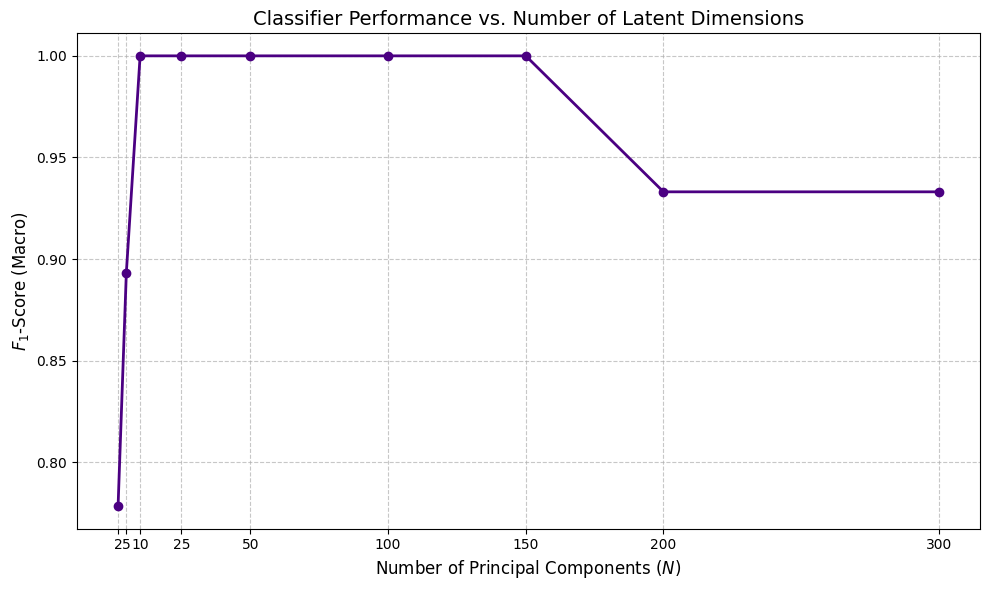

In [4]:
import pandas as pd
import matplotlib.pyplot as plt
from sentence_transformers import SentenceTransformer
from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score


df = pd.read_csv("xkom_laptops_multi_page.csv")
df_clean = df[df['Specifications'] != 'MISSING_SPECS'].copy()
df_clean['Combined_Text'] = df_clean['Combined_Text'].fillna('')

# data has no built in relation so we are making our own with brand names
df_clean['Brand'] = df_clean['Title'].apply(lambda x: str(x).split()[0])
# To make the classification stable, we will only keep the top 5 most common brands
# in case there is a laptop from a single brand, our alg will break when predicting
top_brands = df_clean['Brand'].value_counts().nlargest(5).index
df_filtered = df_clean[df_clean['Brand'].isin(top_brands)].copy()

print(f"Targeting these brands for classification: {list(top_brands)}\n")


print("Vectorizing laptop descriptions...")
model = SentenceTransformer('all-MiniLM-L6-v2')
X = model.encode(df_filtered['Combined_Text'].tolist())
y = df_filtered['Brand']

# Split into 70% training and 30% testing
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)


n_components_list = [2, 5, 10, 25, 50, 100, 150, 200, 300] # will be more than the data we have
f1_scores = []

print("Evaluating Random Forest across PCA dimensions...")
for n in n_components_list:
    max_possible_components = min(X_train.shape[0], X_train.shape[1]) # prevent crashing from unique clues we will have only 179 laptop but our n goes to 300 so this caps it  
    current_n = min(n, max_possible_components) # squish dimenstions, 2, 5, 10...
    
    # Apply PCA
    pca = PCA(n_components=current_n, random_state=42)
    X_train_pca = pca.fit_transform(X_train)
    X_test_pca = pca.transform(X_test)
    
    clf = RandomForestClassifier(n_estimators=100, random_state=42)
    clf.fit(X_train_pca, y_train)
    
    preds = clf.predict(X_test_pca)
    score = f1_score(y_test, preds, average='macro')
    f1_scores.append(score)
    
    print(f"Latent Dimensions: {current_n:3d} | F1-Score: {score:.4f}")

plt.figure(figsize=(10, 6))
plt.plot(n_components_list[:len(f1_scores)], f1_scores, marker='o', linestyle='-', color='indigo', linewidth=2)

plt.title('Classifier Performance vs. Number of Latent Dimensions', fontsize=14)
plt.xlabel('Number of Principal Components ($N$)', fontsize=12)
plt.ylabel('$F_1$-Score (Macro)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.7)
plt.xticks(n_components_list)

plt.tight_layout()
plt.show()



## Task 2: Custom Dataset Creation and 2D Manifold Visualization

Objective
Build a unique dataset from scratch and visualize its underlying high-dimensional structure in a
two-dimensional space.


Loading embedding model...


Loading weights: 100%|██████████| 103/103 [00:00<00:00, 5781.53it/s]


Vectorizing laptop descriptions. This may take a minute...
Running PCA...
Running t-SNE...


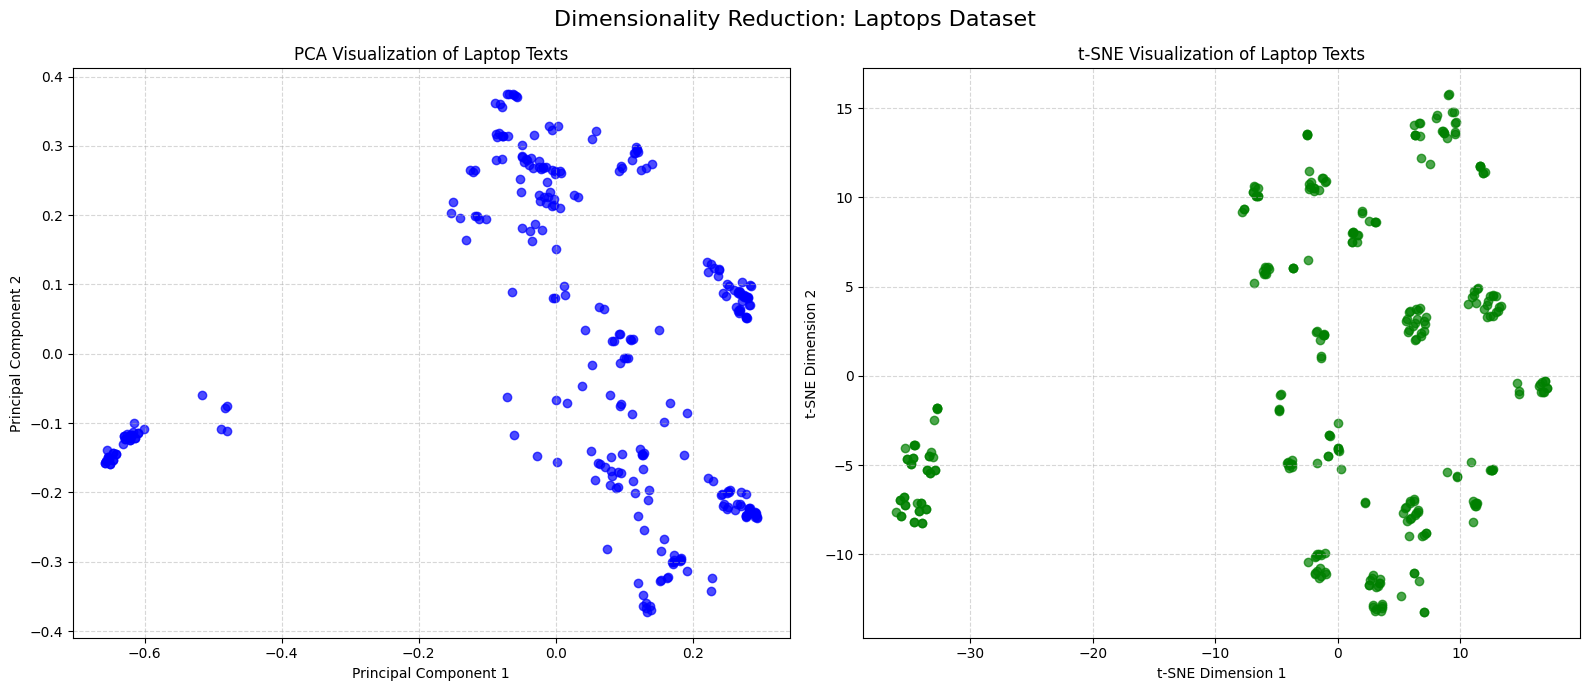

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from sentence_transformers import SentenceTransformer
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

# Load the cleaned data
df = pd.read_csv("xkom_laptops_multi_page.csv")
df['Combined_Text'] = df['Combined_Text'].fillna('')
df_clean = df[df['Specifications'] != 'MISSING_SPECS'].copy()

# the Embedding Model
print("Loading embedding model...")
model = SentenceTransformer('all-MiniLM-L6-v2')


# turns text strings into a list of high-dimensional numbers (384 dimensions)
print("Vectorizing laptop descriptions. This may take a minute...")
embeddings = model.encode(df_clean['Combined_Text'].tolist())

# Dimensionality Reduction (PCA vs t-SNE)
print("Running PCA...")
pca = PCA(n_components=2, random_state=42)
pca_results = pca.fit_transform(embeddings)

print("Running t-SNE...")
tsne = TSNE(n_components=2, perplexity=30, random_state=42)
tsne_results = tsne.fit_transform(embeddings)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 7))

ax1.scatter(pca_results[:, 0], pca_results[:, 1], alpha=0.7, color='blue')
ax1.set_title('PCA Visualization of Laptop Texts')
ax1.set_xlabel('Principal Component 1')
ax1.set_ylabel('Principal Component 2')
ax1.grid(True, linestyle='--', alpha=0.5)

# t-SNE Plot
ax2.scatter(tsne_results[:, 0], tsne_results[:, 1], alpha=0.7, color='green')
ax2.set_title('t-SNE Visualization of Laptop Texts')
ax2.set_xlabel('t-SNE Dimension 1')
ax2.set_ylabel('t-SNE Dimension 2')
ax2.grid(True, linestyle='--', alpha=0.5)

plt.suptitle("Dimensionality Reduction: Laptops Dataset", fontsize=16)
plt.tight_layout()
plt.show()

In [ ]:
import pandas as pd
import numpy as np
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from sentence_transformers import SentenceTransformer
from sklearn import cluster
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import silhouette_score, davies_bouldin_score
from sklearn.neighbors import NearestNeighbors
from sklearn.manifold import TSNE
from sklearn.decomposition import PCA
import plotly.io as pio
pio.renderers.default = "browser"

print("Loading data and embedding model...")
df = pd.read_csv("xkom_laptops_multi_page.csv")
df['Combined_Text'] = df['Combined_Text'].fillna('')
df_clean = df[df['Specifications'] != 'MISSING_SPECS'].copy()

model = SentenceTransformer('all-MiniLM-L6-v2')
embeddings = model.encode(df_clean['Combined_Text'].tolist())
print(f"Generated embeddings shape: {embeddings.shape}")

# when hovering on the graph we get the laptop titles as our classes
laptop_titles = df_clean['Title'].tolist()

# Professor's Functions ( Copied from lab12 )
def find_optimal_clusters(embeddings, max_clusters=10, random_state=42):
    max_clusters = min(max_clusters, len(embeddings) - 1)
    range_n_clusters = list(range(2, max_clusters + 1))
    inertia_values, silhouette_values, davies_bouldin_values = [], [], []

    for n_clusters in range_n_clusters:
        kmeans = KMeans(n_clusters=n_clusters, random_state=random_state, n_init=10)
        cluster_labels = kmeans.fit_predict(embeddings)
        inertia_values.append(kmeans.inertia_)
        silhouette_values.append(silhouette_score(embeddings, cluster_labels) if len(np.unique(cluster_labels)) > 1 else 0)
        davies_bouldin_values.append(davies_bouldin_score(embeddings, cluster_labels))

    optimal_k = {}
    inertia_diffs = np.diff(inertia_values)
    inertia_diffs2 = np.diff(inertia_diffs)
    optimal_k['elbow'] = range_n_clusters[np.argmin(inertia_diffs2) + 1]
    optimal_k['silhouette'] = range_n_clusters[np.argmax(silhouette_values)]
    optimal_k['davies_bouldin'] = range_n_clusters[np.argmin(davies_bouldin_values)]

    # (Plotting code omitted for brevity in terminal, but you can keep the professor's full Plotly figure code here if you want the charts)
    print(f"Optimal Clusters -> Elbow: {optimal_k['elbow']}, Silhouette: {optimal_k['silhouette']}, DB: {optimal_k['davies_bouldin']}")
    return optimal_k

def cluster_embeddings(embeddings, algorithm_name, **kwargs):
    algorithm_class = getattr(cluster, algorithm_name)
    model = algorithm_class(**kwargs)
    if hasattr(model, 'fit_predict'):
        labels = model.fit_predict(embeddings)
    else:
        model.fit(embeddings)
        labels = model.predict(embeddings)
    return labels, model

def estimate_dbscan_eps(embeddings, n_samples=1000, k=5, quantile=0.1):
    sample_data = embeddings if embeddings.shape[0] <= n_samples else embeddings[np.random.choice(embeddings.shape[0], n_samples, replace=False)]
    nbrs = NearestNeighbors(n_neighbors=k + 1).fit(sample_data)
    distances, _ = nbrs.kneighbors(sample_data)
    kdistances = np.sort(distances[:, k])
    eps = np.quantile(kdistances, quantile)
    return eps

def plot_embeddings(embeddings, clustering_results, classes, title="Clustering"):
    reduced = TSNE(n_components=2, perplexity=30, random_state=42).fit_transform(embeddings)
    df_plot = pd.DataFrame({
        "x": reduced[:, 0], "y": reduced[:, 1],
        "Laptop": classes, "Cluster": list(map(str, clustering_results))
    })
    
    fig = px.scatter(
        df_plot, x="x", y="y", color="Cluster", hover_data=["Laptop"], title=title
    )
    fig.update_traces(marker=dict(size=8))
    fig.show()


# 1: finding optimal clusters
print("\n--- Calculating Optimal Clusters ---")
optimal_k_dict = find_optimal_clusters(embeddings, max_clusters=15)
best_k = optimal_k_dict['silhouette'] # Usually the most reliable metric for text

# 2: Manual Cluster Specification (K-Means)
print(f"\n--- Running K-Means with K={best_k} ---")
kmeans_labels, _ = cluster_embeddings(embeddings, 'KMeans', n_clusters=best_k, random_state=42)
plot_embeddings(embeddings, kmeans_labels, laptop_titles, title=f"K-Means Clustering (K={best_k})")

# 3: Algorithm Determines Clusters (DBSCAN)
print("\n--- Running DBSCAN (Auto-determining clusters) ---")

# so dots are mathematically closer
reduced_for_dbscan = PCA(n_components=15, random_state=42).fit_transform(embeddings)

# multiply to widen the search radius
base_eps = estimate_dbscan_eps(reduced_for_dbscan)
wider_eps = base_eps * 1.5
print(f"Original EPS: {base_eps:.3f} | Adjusted EPS: {wider_eps:.3f}")

dbscan_labels, _ = cluster_embeddings(
    reduced_for_dbscan, 'DBSCAN', 
    eps=wider_eps, 
    min_samples=3 
)

plot_embeddings(embeddings, dbscan_labels, laptop_titles, title="DBSCAN Clustering (Adjusted)")

dbscan_labels, _ = cluster_embeddings(
    reduced_for_dbscan, 'DBSCAN', 
    eps=optimal_eps, 
    min_samples=5
)
plot_embeddings(embeddings, dbscan_labels, laptop_titles, title="DBSCAN Clustering")

Loading data and embedding model...


Loading weights: 100%|██████████| 103/103 [00:00<00:00, 5097.68it/s]


Generated embeddings shape: (300, 384)

--- Calculating Optimal Clusters ---
Optimal Clusters -> Elbow: 10, Silhouette: 15, DB: 2

--- Running K-Means with K=15 ---

--- Running DBSCAN (Auto-determining clusters) ---
Original EPS: 0.043 | Adjusted EPS: 0.065

=== Cluster -1 (The Weird Outliers / Noise) ===
- Dell 16 Core 7 150U/16GB/1TB/Win11
- Dell 15 Ryzen 7‑7730U/24GB/1TB/Win11 120Hz
- HP Omnibook X FLIP 14 Ultra 5‑226V/16GB/512/Win11 Touch
- Dell 15 i7‑1355U/32GB/512/Win11 120Hz Czarny
- Lenovo IdeaPad Slim 3‑15 i5‑13420H/16GB/512/Win11

=== Cluster 0 ===
- HP VICTUS 15 Core 5‑210H/24GB/512/Win11 RTX5060 144Hz
- HP VICTUS 15 Core 5‑210H/32GB/1TB/Win11 RTX5050 144Hz
- HP VICTUS 15 Core 5‑210H/32GB/2TB/Win11 RTX5050 144Hz
- HP VICTUS 15 Core 5‑210H/16GB/1TB/Win11 RTX5050 144Hz
- HP VICTUS 15 Core 5‑210H/32GB/512/Win11 RTX5050 144Hz

=== Cluster 1 ===
- Lenovo Legion 5‑15 Ryzen 7‑260/16GB/512/Win11 RTX5050 OLED 165Hz
- Lenovo Legion 5‑15 Ryzen 7‑260/16GB/512 RTX5060 OLED
- Lenovo Legi

Running K-Means tests to find the optimal number of clusters


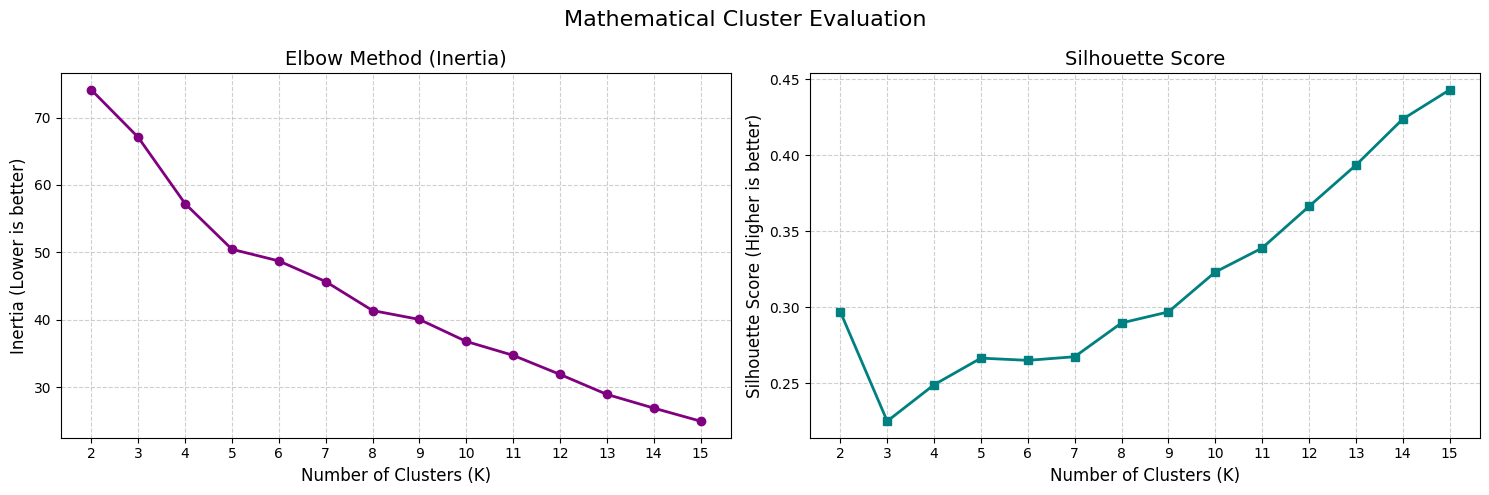

In [ ]:
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

k_range = range(2, 16)
inertia_scores = []
silhouette_scores = []

print("Running K-Means tests to find the optimal number of clusters")

for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init='auto')
    labels = kmeans.fit_predict(embeddings)
    
    inertia_scores.append(kmeans.inertia_)
    
    sil_score = silhouette_score(embeddings, labels)
    silhouette_scores.append(sil_score)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

ax1.plot(k_range, inertia_scores, marker='o', linestyle='-', color='purple', linewidth=2)
ax1.set_title('Elbow Method (Inertia)', fontsize=14)
ax1.set_xlabel('Number of Clusters (K)', fontsize=12)
ax1.set_ylabel('Inertia (Lower is better)', fontsize=12)
ax1.set_xticks(k_range)
ax1.grid(True, linestyle='--', alpha=0.6)

ax2.plot(k_range, silhouette_scores, marker='s', linestyle='-', color='teal', linewidth=2)
ax2.set_title('Silhouette Score', fontsize=14)
ax2.set_xlabel('Number of Clusters (K)', fontsize=12)
ax2.set_ylabel('Silhouette Score (Higher is better)', fontsize=12)
ax2.set_xticks(k_range)
ax2.grid(True, linestyle='--', alpha=0.6)

plt.suptitle("Mathematical Cluster Evaluation", fontsize=16)
plt.tight_layout()
plt.show()